# Adam vs AdaMax on MNIST

This notebook explains the two optimizers from Kingma & Ba (2015), checks the
implementations in `adam_study.optim` against PyTorch, and presents the results of the
experiment grid: logistic regression, an MLP and a CNN on MNIST, the last two with and
without dropout, each trained with Adam and with AdaMax.

The notebook does not train any model. It reads `results/results.json` and
`results/dropout_eval.json`, which are written by

```bash
python -m adam_study.experiments --seeds 5 --epochs 20 --out results
python -m adam_study.dropout_eval --out results
```

To read a different `results.json`, set the environment variable `ADAM_STUDY_RESULTS` to
its path; `dropout_eval.json` is read from the same directory.

In [1]:
%matplotlib inline

import json
import os
import statistics
from pathlib import Path

import torch
from IPython.display import Markdown, display

from adam_study import Adam, AdaMax
from adam_study.dropout_eval import dropout_table
from adam_study.experiments import accuracy_table, summarize, table_order
from adam_study.models import MODEL_LABELS, MODEL_NAMES
from adam_study.plots import dropout_figure, optimizer_figure, summary_figure
from adam_study.train import OPTIMIZER_LABELS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = Path(os.environ.get("ADAM_STUDY_RESULTS", ROOT / "results" / "results.json"))

## Adam (Algorithm 1)

Adam keeps two exponential moving averages for every parameter: one of the stochastic
gradient $g_t = \nabla_\theta f_t(\theta_{t-1})$ and one of its elementwise square. At
update $t = 1, 2, \dots$

$$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1 - \beta_1)\, g_t && \text{first moment estimate} \\
v_t &= \beta_2 v_{t-1} + (1 - \beta_2)\, g_t^2 && \text{second raw moment estimate} \\
\hat m_t &= m_t / (1 - \beta_1^t), \quad \hat v_t = v_t / (1 - \beta_2^t) && \text{bias correction} \\
\theta_t &= \theta_{t-1} - \alpha\, \hat m_t / (\sqrt{\hat v_t} + \epsilon)
\end{aligned}
$$

with $m_0 = v_0 = 0$ and the paper's defaults $\alpha = 0.001$, $\beta_1 = 0.9$,
$\beta_2 = 0.999$ and $\epsilon = 10^{-8}$.

Two properties explain the design:

- **Bias correction.** Because the averages start at zero, they underestimate the moments
  during the first updates. Without the correction, the first update would be
  $m_1 / \sqrt{v_1} = 0.1\, g_1 / \sqrt{0.001\, g_1^2} \approx 3.2$ times $\alpha$ per
  parameter instead of $\alpha$.
- **Scale invariance.** Multiplying the gradient by a positive constant leaves
  $\hat m_t / \sqrt{\hat v_t}$ unchanged, and in typical cases
  $|\hat m_t / \sqrt{\hat v_t}| \le 1$, so each parameter moves by at most about $\alpha$
  per update. This makes $\alpha$ easy to choose.

Adam builds on AdaGrad (Duchi et al., 2011), which adapts a step size per parameter and
suits sparse gradients, and RMSProp (Tieleman & Hinton, 2012), whose moving average of
squared gradients suits non-stationary objectives.

## AdaMax (Algorithm 2)

Adam scales each update by an $L^2$ norm of past gradients. Replacing it with an $L^p$
norm and letting $p \to \infty$ gives a simple recursion, an exponentially weighted
infinity norm:

$$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1 - \beta_1)\, g_t \\
u_t &= \max(\beta_2\, u_{t-1},\ |g_t|) \\
\theta_t &= \theta_{t-1} - \frac{\alpha}{1 - \beta_1^t}\, \frac{m_t}{u_t}
\end{aligned}
$$

A running maximum is not biased towards zero, so only $m_t$ needs a correction, and each
update is bounded by $|\Delta_t| \le \alpha$. The paper suggests $\alpha = 0.002$.

Two details are not specified by the algorithms, and the implementation follows PyTorch
for both: AdaMax adds $\epsilon$ to $|g_t|$ inside the maximum, so $u_t$ stays positive
when a gradient entry has always been zero, and the optional `weight_decay` adds an L2
term $\lambda \theta$ to the gradient before the moments are updated.

## Checking the implementations

`adam_study.optim.Adam` and `adam_study.optim.AdaMax` subclass `torch.optim.Optimizer`.
The cell below gives each of them and the matching PyTorch optimizer the same 1,000 random
gradients in float64 and prints the largest difference between the resulting parameters.
The test suite runs the same comparison for more settings, and also checks
`state_dict()`/`load_state_dict()` and learning-rate schedulers.

In [2]:
def max_difference(ours_cls, torch_cls, steps=1000, **kwargs):
    generator = torch.Generator().manual_seed(0)
    start = torch.randn(100, generator=generator, dtype=torch.float64)
    ours, theirs = start.clone().requires_grad_(), start.clone().requires_grad_()
    ours_opt, torch_opt = ours_cls([ours], **kwargs), torch_cls([theirs], **kwargs)
    for _ in range(steps):
        grad = torch.randn(100, generator=generator, dtype=torch.float64)
        ours.grad, theirs.grad = grad.clone(), grad.clone()
        ours_opt.step()
        torch_opt.step()
    return (ours - theirs).abs().max().item()


for ours_cls, torch_cls in [(Adam, torch.optim.Adam), (AdaMax, torch.optim.Adamax)]:
    for weight_decay in (0.0, 0.01):
        diff = max_difference(ours_cls, torch_cls, lr=0.01, weight_decay=weight_decay)
        print(f"{ours_cls.__name__:6} weight_decay={weight_decay:<4} max |diff| = {diff:.1e}")

Adam   weight_decay=0.0  max |diff| = 6.7e-16
Adam   weight_decay=0.01 max |diff| = 6.7e-16


AdaMax weight_decay=0.0  max |diff| = 4.4e-16
AdaMax weight_decay=0.01 max |diff| = 4.4e-16


## Setup

| Setting | Value |
|---|---|
| Data | MNIST: 60,000 training and 10,000 test images, pixel values scaled to [0, 1] |
| Logistic regression | 784 -> 10 |
| MLP | 784-1000-1000-10, ReLU |
| CNN | two stages of 5x5 convolution, 3x3 max-pooling with stride 2 and ReLU (10 and 50 channels), a 200-unit ReLU layer, output layer |
| Dropout | none, or p = 0.2 before the output layer of the MLP and the CNN |
| Optimizers | Adam and AdaMax, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$ |
| Step size | constant $\alpha = 0.001$ for both, no L2 penalty |
| Training | batch size 128, cross-entropy loss |

Each run records, after every epoch, the mean training loss over the epoch's minibatches,
and the loss and accuracy on the test set with dropout switched off. Runs with the same
seed start from the same initial weights and see the same minibatches and dropout masks,
so at a given seed Adam and AdaMax differ only in their updates.

The cell below shows the settings stored with the results and what was run.

In [3]:
saved = json.loads(RESULTS.read_text())
runs = saved["runs"]
print("settings:", saved["settings"])
print(f"{len(runs)} runs, seeds {sorted({run['seed'] for run in runs})}")
print("devices:", sorted({run["device"] for run in runs}))
print("torch:", sorted({run["torch"] for run in runs}))
print(f"training time summed over runs: {sum(run['seconds'] for run in runs) / 3600:.1f} h")

settings: {'epochs': 20, 'batch_size': 128, 'lr': 0.001, 'schedule': 'constant', 'weight_decay': 0.0}
50 runs, seeds [0, 1, 2, 3, 4]
devices: ['cpu']
torch: ['2.15.0+cu132']
training time summed over runs: 5.9 h


## Final test accuracy

Test accuracy after the last epoch, as mean ± standard deviation over seeds. The last
column is the difference Adam - AdaMax computed seed by seed; the two runs in each pair
start from the same initial weights and see the same minibatches.

In [4]:
display(Markdown(accuracy_table(runs)))

| Model | Dropout | Adam | AdaMax | Adam - AdaMax |
|---|---|---|---|---|
| Logistic regression | none | 92.73 ± 0.04 | 92.44 ± 0.04 | +0.29 ± 0.06 |
| MLP | none | 98.22 ± 0.22 | 98.31 ± 0.03 | -0.08 ± 0.23 |
| MLP | 0.2 | 98.08 ± 0.20 | 98.35 ± 0.05 | -0.27 ± 0.19 |
| CNN | none | 99.09 ± 0.15 | 99.17 ± 0.08 | -0.08 ± 0.18 |
| CNN | 0.2 | 99.23 ± 0.10 | 99.23 ± 0.11 | 0.00 ± 0.09 |

The final losses, again as mean ± standard deviation over seeds:

In [5]:
def dropout_label(dropout):
    return f"{dropout:g}" if dropout else "none"


lines = [
    "| Model | Dropout | Optimizer | Training loss | Test loss |",
    "|---|---|---|---|---|",
]
for row in summarize(runs):
    lines.append(
        f"| {MODEL_LABELS[row['model']]} | {dropout_label(row['dropout'])} "
        f"| {OPTIMIZER_LABELS[row['optimizer']]} "
        f"| {row['train_loss_mean']:.4f} ± {row['train_loss_std']:.4f} "
        f"| {row['test_loss_mean']:.4f} ± {row['test_loss_std']:.4f} |"
    )
display(Markdown("\n".join(lines)))

| Model | Dropout | Optimizer | Training loss | Test loss |
|---|---|---|---|---|
| Logistic regression | none | Adam | 0.2457 ± 0.0002 | 0.2620 ± 0.0007 |
| Logistic regression | none | AdaMax | 0.2736 ± 0.0002 | 0.2717 ± 0.0003 |
| MLP | none | Adam | 0.0097 ± 0.0028 | 0.1047 ± 0.0160 |
| MLP | none | AdaMax | 0.0003 ± 0.0002 | 0.0790 ± 0.0029 |
| MLP | 0.2 | Adam | 0.0086 ± 0.0033 | 0.1198 ± 0.0180 |
| MLP | 0.2 | AdaMax | 0.0007 ± 0.0001 | 0.0745 ± 0.0029 |
| CNN | none | Adam | 0.0060 ± 0.0008 | 0.0348 ± 0.0057 |
| CNN | none | AdaMax | 0.0152 ± 0.0005 | 0.0260 ± 0.0019 |
| CNN | 0.2 | Adam | 0.0080 ± 0.0009 | 0.0291 ± 0.0036 |
| CNN | 0.2 | AdaMax | 0.0184 ± 0.0006 | 0.0240 ± 0.0028 |

## Training curves

Each curve is the mean over seeds and the band is ± one standard deviation. Color marks
the optimizer and line style the dropout setting. Loss axes use a log scale when the
curves on them span more than a factor of ten.

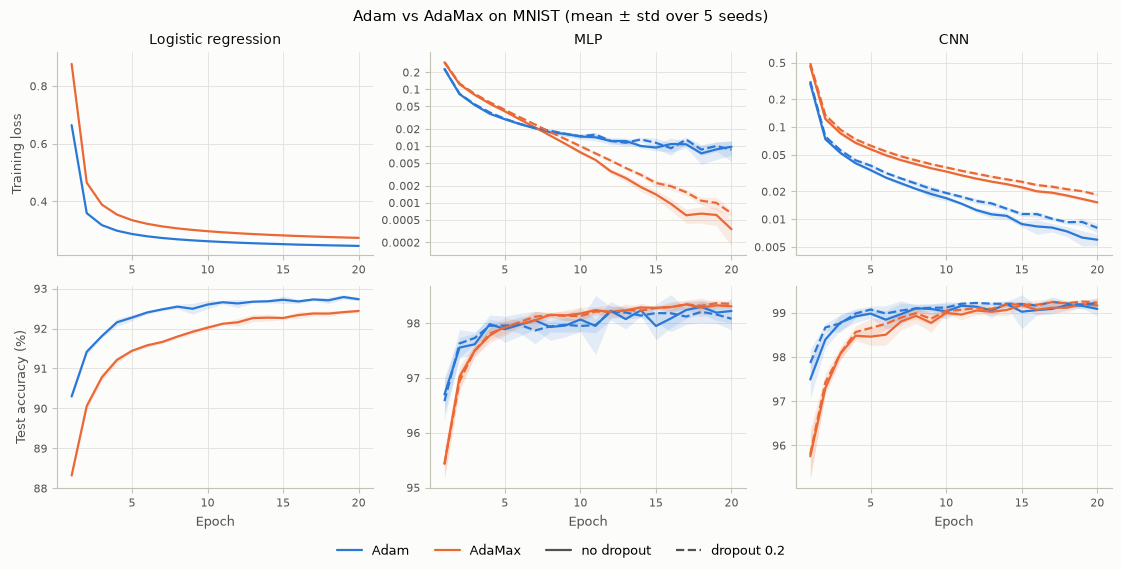

In [6]:
display(summary_figure(runs))

### Adam vs AdaMax for each model

The same curves, one figure per model, with one row per dropout setting.

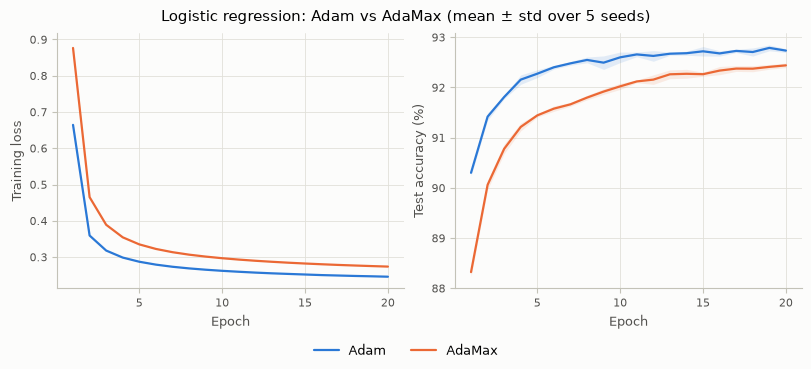

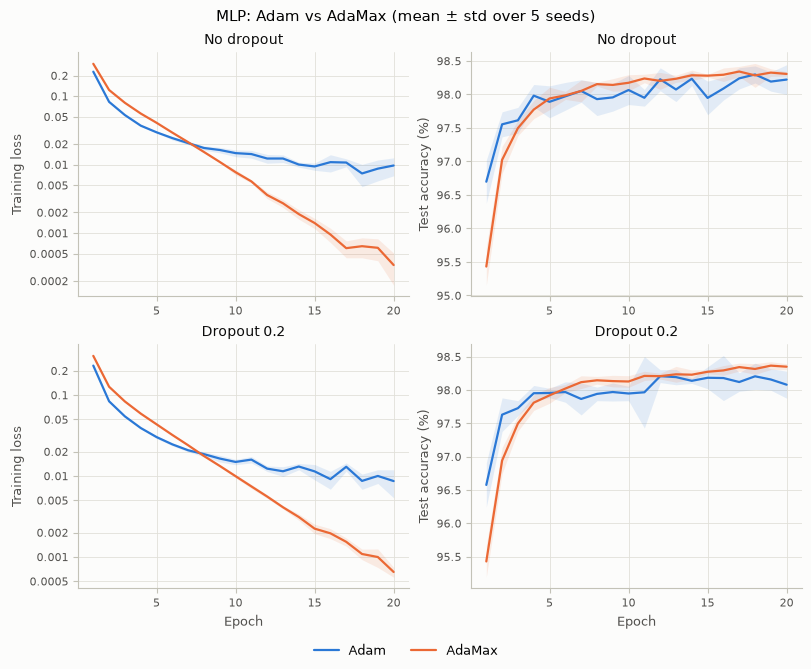

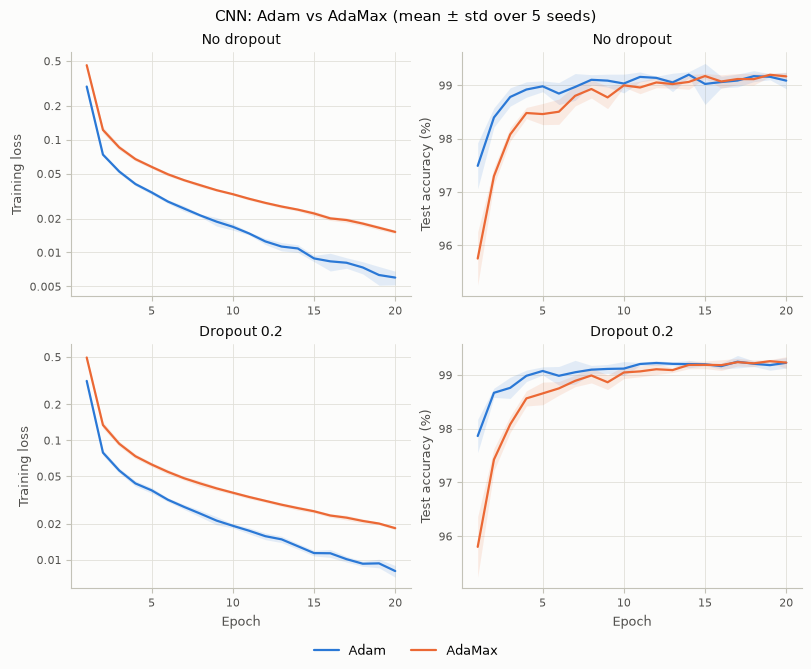

In [7]:
for model in MODEL_NAMES:
    figure = optimizer_figure(runs, model)
    if figure is not None:
        display(figure)

### Dropout

The training loss is measured with dropout active, the test loss and accuracy with dropout
switched off. For the MLP, the test loss is lowest after a few epochs and then rises while
the test accuracy still improves slightly: the network keeps fitting the training set and
becomes more confident, including on the test images it misclassifies. The rise is steeper
with Adam than with AdaMax. For the MLP and the CNN with either optimizer, the average
effect of dropout (p = 0.2) on the final test accuracy is smaller than its standard
deviation over seeds.

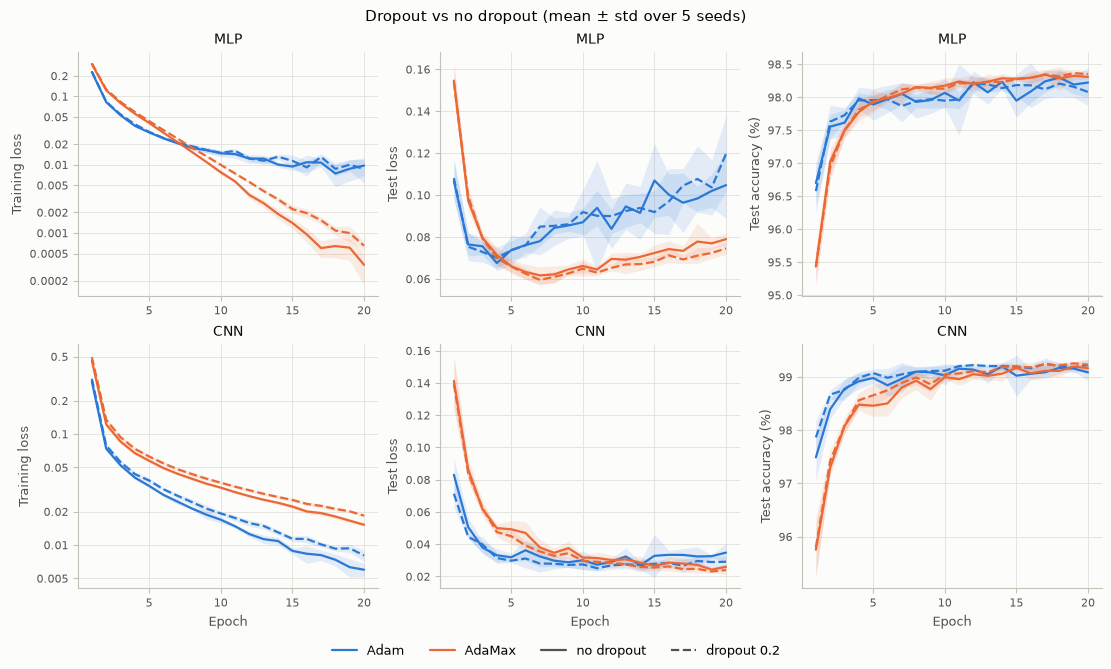

In [8]:
figure = dropout_figure(runs)
if figure is not None:
    display(figure)

## Comparison with the 2022 results

The 2022 version of this project ran each configuration once, without a seed. The table
puts its test accuracies next to the five new runs.

In [9]:
accuracy_2022 = {
    ("logreg", 0.0, "adam"): 92.69,
    ("logreg", 0.0, "adamax"): 92.38,
    ("mlp", 0.0, "adam"): 98.17,
    ("mlp", 0.0, "adamax"): 98.33,
    ("mlp", 0.2, "adam"): 98.43,
    ("mlp", 0.2, "adamax"): 98.14,
    ("cnn", 0.0, "adam"): 99.21,
    ("cnn", 0.0, "adamax"): 99.09,
    ("cnn", 0.2, "adam"): 99.21,
    ("cnn", 0.2, "adamax"): 99.09,
}


def position(value, low, high):
    return "below" if value < low else "above" if value > high else "inside"


header = ["Model", "Dropout", "Optimizer", "2022 (one run)", "Now: mean ± std", "Now: range"]
header.append("2022 vs range")
lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
for row in summarize(runs):
    key = (row["model"], row["dropout"], row["optimizer"])
    finals = [r["test_acc"][-1] for r in runs if (r["model"], r["dropout"], r["optimizer"]) == key]
    old = accuracy_2022[key]
    lines.append(
        f"| {MODEL_LABELS[row['model']]} | {dropout_label(row['dropout'])} "
        f"| {OPTIMIZER_LABELS[row['optimizer']]} | {old:.2f} "
        f"| {row['test_acc_mean']:.2f} ± {row['test_acc_std']:.2f} "
        f"| {min(finals):.2f} to {max(finals):.2f} | {position(old, min(finals), max(finals))} |"
    )
display(Markdown("\n".join(lines)))

| Model | Dropout | Optimizer | 2022 (one run) | Now: mean ± std | Now: range | 2022 vs range |
|---|---|---|---|---|---|---|
| Logistic regression | none | Adam | 92.69 | 92.73 ± 0.04 | 92.67 to 92.76 | inside |
| Logistic regression | none | AdaMax | 92.38 | 92.44 ± 0.04 | 92.38 to 92.50 | inside |
| MLP | none | Adam | 98.17 | 98.22 ± 0.22 | 97.99 to 98.49 | inside |
| MLP | none | AdaMax | 98.33 | 98.31 ± 0.03 | 98.27 to 98.34 | inside |
| MLP | 0.2 | Adam | 98.43 | 98.08 ± 0.20 | 97.89 to 98.30 | above |
| MLP | 0.2 | AdaMax | 98.14 | 98.35 ± 0.05 | 98.29 to 98.40 | below |
| CNN | none | Adam | 99.21 | 99.09 ± 0.15 | 98.93 to 99.27 | inside |
| CNN | none | AdaMax | 99.09 | 99.17 ± 0.08 | 99.08 to 99.25 | inside |
| CNN | 0.2 | Adam | 99.21 | 99.23 ± 0.10 | 99.08 to 99.32 | inside |
| CNN | 0.2 | AdaMax | 99.09 | 99.23 ± 0.11 | 99.12 to 99.35 | below |

Without dropout, every 2022 value lies within the range of the five new runs, which is
consistent with run-to-run variation. With dropout, three of the four 2022 values lie
outside it.

The 2022 code had four problems that this version fixes:

- the dropout models were tested with dropout still active, because the code never
  called `model.eval()`;
- each configuration ran once, without a seed;
- the loss curves recorded only the last minibatch of each epoch;
- the Adam vs AdaMax and dropout comparison plots shifted the second curve one epoch to
  the left (`plt.plot(x, a, b)` plots `b` against 0, 1, 2, ...).

The last two affected only the plots. To measure the first,
`python -m adam_study.dropout_eval` retrains every dropout run with the same settings and
seed, and tests the final model twice: with dropout off, as in the table above, and with
dropout on, as the 2022 code did, averaged over 20 passes over the test set. The first
table below shows both accuracies and their difference, computed run by run. The second
puts the 2022 values next to the range of the new runs tested with dropout on.

In [10]:
def run_key(run):
    return run["model"], run["optimizer"], run["dropout"], run["seed"]


dropout_eval_path = RESULTS.with_name("dropout_eval.json")
if dropout_eval_path.exists():
    dropout_runs = json.loads(dropout_eval_path.read_text())["runs"]
    display(Markdown(dropout_table(dropout_runs)))
    final_acc = {run_key(run): run["test_acc"][-1] for run in runs}
    same = sum(run["test_acc_dropout_off"] == final_acc.get(run_key(run)) for run in dropout_runs)
    print(f"Same accuracy as {RESULTS.name} with dropout off: {same} of {len(dropout_runs)} runs")

    # The 2022 values next to the new runs tested the same way, with dropout on.
    accuracy_on = {}
    for run in dropout_runs:
        key = (run["model"], run["dropout"], run["optimizer"])
        accuracy_on.setdefault(key, []).append(statistics.fmean(run["test_acc_dropout_on"]))
    header = ["Model", "Dropout", "Optimizer", "2022 (one run)", "Now, dropout on: range"]
    header.append("2022 vs range")
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    for key, accs in sorted(accuracy_on.items(), key=lambda item: table_order(*item[0])):
        model, dropout, optimizer = key
        low, high, old = min(accs), max(accs), accuracy_2022[key]
        lines.append(
            f"| {MODEL_LABELS[model]} | {dropout_label(dropout)} | {OPTIMIZER_LABELS[optimizer]} "
            f"| {old:.2f} | {low:.2f} to {high:.2f} | {position(old, low, high)} |"
        )
    display(Markdown("\n".join(lines)))
else:
    print(f"{dropout_eval_path} not found; run python -m adam_study.dropout_eval")

| Model | Dropout | Optimizer | Dropout off | Dropout on | Off - on |
|---|---|---|---|---|---|
| MLP | 0.2 | Adam | 98.08 ± 0.20 | 98.04 ± 0.20 | +0.04 ± 0.01 |
| MLP | 0.2 | AdaMax | 98.35 ± 0.05 | 98.32 ± 0.05 | +0.03 ± 0.03 |
| CNN | 0.2 | Adam | 99.23 ± 0.10 | 99.11 ± 0.12 | +0.12 ± 0.02 |
| CNN | 0.2 | AdaMax | 99.23 ± 0.11 | 99.13 ± 0.10 | +0.10 ± 0.03 |

Same accuracy as results.json with dropout off: 20 of 20 runs


| Model | Dropout | Optimizer | 2022 (one run) | Now, dropout on: range | 2022 vs range |
|---|---|---|---|---|---|
| MLP | 0.2 | Adam | 98.43 | 97.86 to 98.26 | above |
| MLP | 0.2 | AdaMax | 98.14 | 98.27 to 98.38 | below |
| CNN | 0.2 | Adam | 99.21 | 98.95 to 99.22 | inside |
| CNN | 0.2 | AdaMax | 99.09 | 99.00 to 99.24 | inside |

Testing with dropout on lowers the accuracy on average by about 0.1 points for the CNN and
by 0.03 to 0.04 points for the MLP. Tested that way, the five new CNN runs span both 2022
CNN values, so testing with dropout on is enough to explain the small CNN gap. On the MLP
with dropout, the 2022 Adam value is above and the AdaMax value below every new run,
whichever way the runs are tested; the new runs do not account for that ranking, and with
one unseeded run per configuration its cause cannot be checked.

The alpha / sqrt(t) decay and L2 penalty described in the 2022 proposal never took effect
in that code, so its runs used a constant step size without a penalty, the same settings
as above.

## Limitations

- Both optimizers use the same step size, 0.001. The paper suggests 0.002 for AdaMax, and
  no hyperparameters were tuned, so the comparison is between default-like settings rather
  than between the best each optimizer can do.
- MNIST is easy for all three models, so the differences between optimizers are small
  compared with the differences between models.
- Each run lasts 20 epochs; longer training could change the ranking.